In [2]:

# WEEK 6 - DAY 1
# Purpose: Inspect project folders and dataset metadata
# without importing PyTorch.

from pathlib import Path
import pandas as pd
import os
import sys

# Display the active Python environment
print("Python:", sys.executable)
print("Current working directory:", Path.cwd())

# Detect project root
CURRENT = Path.cwd()

if CURRENT.name.lower() == "notebooks":
    ROOT = CURRENT.parent
else:
    ROOT = CURRENT

RESULTS_DIR = ROOT / "results"
MODELS_DIR = ROOT / "models"

print("\nProject root:", ROOT)
print("Results folder:", RESULTS_DIR.exists())
print("Models folder:", MODELS_DIR.exists())

# Check important CSV files
required_files = [
    "train_videos.csv",
    "validation_videos.csv",
    "test_videos.csv",
    "final_face_metadata.csv",
    "face_metadata.csv",
    "resnet50_preliminary_results.csv",
    "resnet50_confusion_matrix.csv"
]

print("\n========== FILE CHECK ==========")

for filename in required_files:
    path = RESULTS_DIR / filename
    print(filename, ":", "FOUND" if path.exists() else "NOT FOUND")

# Inspect CSV columns and sample records
print("\n========== CSV INSPECTION ==========")

for filename in required_files:
    path = RESULTS_DIR / filename

    if path.exists():
        try:
            df = pd.read_csv(path, nrows=5)
            print("\nFile:", filename)
            print("Columns:", df.columns.tolist())
            print(df.head(2).to_string(index=False))
        except Exception as e:
            print("Error reading", filename, ":", e)

# Check existing model checkpoints
print("\n========== CHECKPOINTS ==========")

if MODELS_DIR.exists():
    files = list(MODELS_DIR.rglob("*.pth"))
    files += list(MODELS_DIR.rglob("*.pt"))
    print(files if files else "No checkpoint found.")


Python: c:\Users\HIMANSHU\Desktop\minor project 1\.venv\Scripts\python.exe
Current working directory: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\notebooks

Project root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Results folder: True
Models folder: True

========== FILE CHECK ==========
train_videos.csv : FOUND
validation_videos.csv : FOUND
test_videos.csv : FOUND
final_face_metadata.csv : FOUND
face_metadata.csv : FOUND
resnet50_preliminary_results.csv : FOUND
resnet50_confusion_matrix.csv : FOUND

========== CSV INSPECTION ==========

File: train_videos.csv
Columns: ['video_path', 'video_name', 'label', 'class_name']
                                      video_path video_name  label class_name
  ..\datasets\Celeb-DF-v2\YouTube-real\00262.mp4      00262      0       Real
..\datasets\Celeb-DF-v2\Celeb-real\id58_0008.mp4  id58_0008      0       Real

File: validation_videos.csv
Columns: ['video_path', 'video_name', 'label', 'class_name']
                       

In [3]:
# WEEK 6 - Step 2: Inspect dataset metadata
# Purpose: Check image paths, labels, and train/validation/test data
# before writing the model evaluation code.

from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
RESULTS = ROOT / "results"

files = [
    "final_face_metadata.csv",
    "face_metadata.csv",
    "train_videos.csv",
    "validation_videos.csv",
    "test_videos.csv"
]

for filename in files:
    file_path = RESULTS / filename

    print("\n" + "=" * 60)
    print("FILE:", filename)

    if not file_path.exists():
        print("NOT FOUND")
        continue

    df = pd.read_csv(file_path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))
    print("\nData types:")
    print(df.dtypes.to_string())

# Check checkpoint file sizes
print("\n" + "=" * 60)
print("AVAILABLE MODEL CHECKPOINTS")

for file_path in (ROOT / "models").glob("*.pth"):
    print(file_path.name, "| Size:", round(file_path.stat().st_size / (1024 * 1024), 2), "MB")


FILE: final_face_metadata.csv
Shape: (61641, 8)
Columns: ['video_path', 'video_id', 'face_path', 'label', 'class_name', 'file_exists', 'image_size', 'split']

First 3 rows:
                                                                                           video_path video_id                                         face_path  label class_name  file_exists image_size split
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4 id0_0000 results\processed_faces\real\id0_0000_face_00.jpg      0       real         True (224, 224) train
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4 id0_0000 results\processed_faces\real\id0_0000_face_01.jpg      0       real         True (224, 224) train
c:\Users\Raja Kumar\OneDrive\Desktop\DEEP FAKE DETECTION\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4 id0_0000 results\processed_faces\real\id0_0000_face_02.jpg      0       real         True (224, 2

In [4]:

# WEEK 6 - Step 3
# Purpose: Verify actual image availability and dataset split.
# This prevents training with incorrect or missing image paths.

from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent
RESULTS = ROOT / "results"

df = pd.read_csv(RESULTS / "final_face_metadata.csv")

# Check whether face images exist in the current project
def resolve_face_path(path):
    p = Path(str(path))
    if p.is_absolute():
        return p
    return ROOT / p

df["actual_path"] = df["face_path"].apply(resolve_face_path)
df["actually_exists"] = df["actual_path"].apply(lambda p: p.is_file())

print("PROJECT ROOT:", ROOT)
print("\nIMAGE PATH CHECK")
print("Total metadata rows:", len(df))
print("CSV says file_exists=True:", df["file_exists"].sum())
print("Actually found in current project:", df["actually_exists"].sum())
print("Actually missing:", (~df["actually_exists"]).sum())

print("\nSPLIT DISTRIBUTION")
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))

print("\nIMAGE PATH EXAMPLES")
for _, row in df.head(5).iterrows():
    print("Stored:", row["face_path"])
    print("Resolved:", row["actual_path"])
    print("Exists:", row["actually_exists"])
    print()

print("\nCHECKPOINT")
checkpoint = ROOT / "models" / "week4_resnet50.pth"
print("Checkpoint exists:", checkpoint.exists())
if checkpoint.exists():
    print("Checkpoint size MB:", round(checkpoint.stat().st_size / (1024 * 1024), 2))


PROJECT ROOT: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project

IMAGE PATH CHECK
Total metadata rows: 61641
CSV says file_exists=True: 61641
Actually found in current project: 61641
Actually missing: 0

SPLIT DISTRIBUTION
label     0      1
split             
test   1711  10610
train  5520  33930
val    1380   8490

IMAGE PATH EXAMPLES
Stored: results\processed_faces\real\id0_0000_face_00.jpg
Resolved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces\real\id0_0000_face_00.jpg
Exists: True

Stored: results\processed_faces\real\id0_0000_face_01.jpg
Resolved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces\real\id0_0000_face_01.jpg
Exists: True

Stored: results\processed_faces\real\id0_0000_face_02.jpg
Resolved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\processed_faces\real\id0_0000_face_02.jpg
Exists: True

Stored: results\processed_faces\real\id0_0000_face_03.jpg
Resolved: c:\Users\HIMANSHU\Deskt

In [7]:

# WEEK 6 - STEP 1 (UPDATED)
# Purpose: Inspect the existing trusted ResNet50 checkpoint.

from pathlib import Path
import torch
import torch._utils as torch_utils

ROOT = Path.cwd().parent
CHECKPOINT = ROOT / "models" / "week4_resnet50.pth"

# Explicitly attach PyTorch utility module
torch._utils = torch_utils

print("PyTorch:", torch.__version__)
print("Project root:", ROOT)
print("Checkpoint found:", CHECKPOINT.exists())
print("GPU available:", torch.cuda.is_available())

if not CHECKPOINT.exists():
    raise FileNotFoundError(CHECKPOINT)

print("Checkpoint size:", round(CHECKPOINT.stat().st_size / (1024 * 1024), 2), "MB")

try:
    checkpoint = torch.load(
        CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint loaded successfully!")
    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys())[:30])

except Exception as e:
    print("\nCheckpoint loading failed:")
    print(type(e).__name__, str(e))


PyTorch: 2.11.0+cu128
Project root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Checkpoint found: True
GPU available: True
Checkpoint size: 89.99 MB

Checkpoint loading failed:
AttributeError module 'torch' has no attribute 'dtype'


In [6]:

# WEEK 6 - STEP 2
# Purpose: Check PyTorch internal utilities and load our trusted checkpoint.

import torch
from pathlib import Path

ROOT = Path.cwd().parent
CHECKPOINT = ROOT / "models" / "week4_resnet50.pth"

print("PyTorch version:", torch.__version__)

# Verify PyTorch internal utility module
try:
    import torch._utils
    print("Torch internal utilities: Available")
except Exception as e:
    print("Torch utility error:", repr(e))

# Load only our own trusted project checkpoint
try:
    checkpoint = torch.load(
        CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )

    print("\nCheckpoint loaded successfully!")
    print("Checkpoint type:", type(checkpoint))

    if isinstance(checkpoint, dict):
        print("Checkpoint keys:", list(checkpoint.keys())[:30])

except Exception as e:
    print("\nCheckpoint loading failed:")
    print(type(e).__name__, str(e))


PyTorch version: 2.11.0+cu128
Torch internal utilities: Available

Checkpoint loading failed:
AttributeError module 'torch' has no attribute '_utils'


In [1]:

# WEEK 6 - PyTorch diagnostic
# Purpose: Check whether PyTorch is correctly initialized.

import torch
from pathlib import Path
import zipfile

ROOT = Path.cwd().parent
CHECKPOINT = ROOT / "models" / "week4_resnet50.pth"

print("PyTorch:", torch.__version__)
print("Torch location:", torch.__file__)
print("torch.dtype available:", hasattr(torch, "dtype"))
print("torch.float32 available:", hasattr(torch, "float32"))
print("CUDA:", torch.cuda.is_available())

print("\nCheckpoint is ZIP format:",
      zipfile.is_zipfile(CHECKPOINT))

if zipfile.is_zipfile(CHECKPOINT):
    with zipfile.ZipFile(CHECKPOINT) as z:
        print("Checkpoint internal files:")
        for name in z.namelist()[:10]:
            print(name)

print("\nExisting Week 4 history:")
history = ROOT / "results" / "week4_resnet50_history.csv"
print("Found:", history.exists())

if history.exists():
    import pandas as pd
    print(pd.read_csv(history).to_string(index=False))


PyTorch: 2.11.0+cu128
Torch location: c:\Users\HIMANSHU\Desktop\minor project 1\.venv\Lib\site-packages\torch\__init__.py
torch.dtype available: True
torch.float32 available: True
CUDA: True

Checkpoint is ZIP format: True
Checkpoint internal files:
week4_resnet50/data.pkl
week4_resnet50/.format_version
week4_resnet50/.storage_alignment
week4_resnet50/byteorder
week4_resnet50/data/0
week4_resnet50/data/1
week4_resnet50/data/2
week4_resnet50/data/3
week4_resnet50/data/4
week4_resnet50/data/5

Existing Week 4 history:
Found: True
 epoch  train_loss  val_loss
     1    0.539551  1.791371
     2    0.439606  0.926945
     3    0.406714  0.869280
     4    0.385976  1.192282
     5    0.370223  0.999889


In [2]:

# WEEK 6 - STEP 4
# Purpose: Safely load the saved ResNet50 state dictionary.

import torch
from pathlib import Path

ROOT = Path.cwd().parent
CHECKPOINT = ROOT / "models" / "week4_resnet50.pth"

print("PyTorch:", torch.__version__)
print("Checkpoint:", CHECKPOINT.exists())

# Load the saved weights only; do not load arbitrary Python objects.
state_dict = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

print("\nCheckpoint loaded successfully!")
print("Object type:", type(state_dict))
print("Number of parameters:", len(state_dict))

print("\nFirst 10 parameter names and shapes:")
for name, value in list(state_dict.items())[:10]:
    print(name, tuple(value.shape))

# Verify final ResNet50 classification layer
print("\nFinal layer weight:", state_dict["fc.weight"].shape)
print("Final layer bias:", state_dict["fc.bias"].shape)


PyTorch: 2.11.0+cu128
Checkpoint: True

Checkpoint loaded successfully!
Object type: <class 'collections.OrderedDict'>
Number of parameters: 320

First 10 parameter names and shapes:
conv1.weight (64, 3, 7, 7)
bn1.weight (64,)
bn1.bias (64,)
bn1.running_mean (64,)
bn1.running_var (64,)
bn1.num_batches_tracked ()
layer1.0.conv1.weight (64, 64, 1, 1)
layer1.0.bn1.weight (64,)
layer1.0.bn1.bias (64,)
layer1.0.bn1.running_mean (64,)

Final layer weight: torch.Size([1, 2048])
Final layer bias: torch.Size([1])


In [3]:

# WEEK 6 - STEP 5
# Purpose: Final evaluation of the trained ResNet50 on the unseen test split.
# The existing checkpoint is loaded; no new training is performed.

from pathlib import Path
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# 1. Project paths and device
ROOT = Path.cwd().parent
RESULTS = ROOT / "results"
MODEL_PATH = ROOT / "models" / "week4_resnet50.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

# 2. Load metadata and select test images
df = pd.read_csv(RESULTS / "final_face_metadata.csv")
test_df = df[df["split"].str.lower() == "test"].copy()

def resolve_path(path):
    p = Path(str(path))
    return p if p.is_absolute() else ROOT / p

test_df["actual_path"] = test_df["face_path"].apply(resolve_path)
test_df = test_df[test_df["actual_path"].apply(lambda p: p.is_file())]
test_df = test_df.reset_index(drop=True)

print("Test images:", len(test_df))
print("Test labels:\n", test_df["label"].value_counts())

# 3. Image preprocessing
# Match the ImageNet normalization used by pretrained ResNet50.
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 4. Dataset class
class FaceTestDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]
        image = Image.open(row["actual_path"]).convert("RGB")
        image = self.transform(image)
        label = int(row["label"])
        return image, label

test_dataset = FaceTestDataset(test_df, test_transform)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

# 5. Rebuild the exact ResNet50 architecture
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 1)

# Load the existing trained weights
state_dict = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(state_dict, strict=True)
model = model.to(DEVICE)
model.eval()

print("\nResNet50 checkpoint loaded successfully.")

# 6. Generate predictions
all_labels = []
all_probabilities = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(DEVICE)

        logits = model(images).squeeze(1)
        probabilities = torch.sigmoid(logits)

        all_labels.extend(labels.numpy().tolist())
        all_probabilities.extend(probabilities.cpu().numpy().tolist())

y_true = np.array(all_labels)
y_prob = np.array(all_probabilities)
y_pred = (y_prob >= 0.5).astype(int)

# 7. Calculate evaluation metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_true, y_prob)

print("\n========== FINAL RESNET50 RESULTS ==========")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

# 8. Confusion matrix and classification report
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(cm)

report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    output_dict=True,
    zero_division=0
)

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Real", "Fake"],
    zero_division=0
))

# 9. Save final evaluation files
RESULTS.mkdir(exist_ok=True)

pd.DataFrame([{
    "Model": "ResNet50",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1,
    "ROC-AUC": roc_auc,
    "Test_Images": len(y_true)
}]).to_csv(RESULTS / "week6_final_metrics.csv", index=False)

pd.DataFrame(
    cm,
    index=["Actual Real", "Actual Fake"],
    columns=["Predicted Real", "Predicted Fake"]
).to_csv(RESULTS / "week6_confusion_matrix.csv")

pd.DataFrame(report).transpose().to_csv(
    RESULTS / "week6_classification_report.csv"
)

predictions = test_df[["video_id", "face_path", "label"]].copy()
predictions["predicted_label"] = y_pred
predictions["probability_deepfake"] = y_prob

predictions.to_csv(
    RESULTS / "week6_test_predictions.csv",
    index=False
)

print("\nAll Week 6 evaluation files saved successfully.")
print("Results folder:", RESULTS)


Device: cuda
Test images: 12321
Test labels:
 label
1    10610
0     1711
Name: count, dtype: int64

ResNet50 checkpoint loaded successfully.

========== FINAL RESNET50 RESULTS ==========
Accuracy : 0.8076
Precision: 0.9391
Recall   : 0.8304
F1-score : 0.8815
ROC-AUC  : 0.8331

Confusion Matrix:
[[1140  571]
 [1799 8811]]

Classification Report:
              precision    recall  f1-score   support

        Real       0.39      0.67      0.49      1711
        Fake       0.94      0.83      0.88     10610

    accuracy                           0.81     12321
   macro avg       0.66      0.75      0.69     12321
weighted avg       0.86      0.81      0.83     12321


All Week 6 evaluation files saved successfully.
Results folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results


Training history:
 epoch  train_loss  val_loss
     1    0.539551  1.791371
     2    0.439606  0.926945
     3    0.406714  0.869280
     4    0.385976  1.192282
     5    0.370223  0.999889


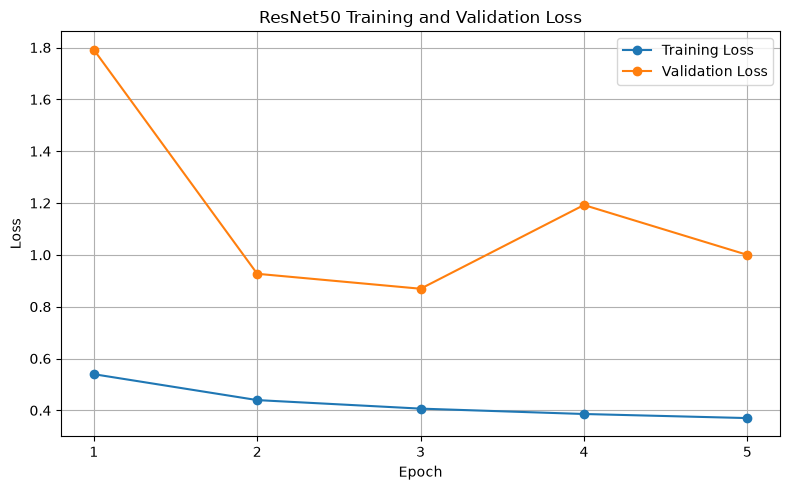


Best validation-loss epoch: 3
Best validation loss: 0.8693
Final training loss: 0.3702
Final validation loss: 0.9999


WEEK 6 - FINAL MODEL EVALUATION AND ANALYSIS

Model: ResNet50
Dataset: Celeb-DF-v2
Test images: 12321

Accuracy: 0.8076
Precision (Fake): 0.9391
Recall (Fake): 0.8304
F1-score (Fake): 0.8815
ROC-AUC: 0.8331

Best validation-loss epoch: 3
Best validation loss: 0.8693

Training observation:
Possible overfitting observed after epoch 3: validation loss increased after its minimum while training loss decreased.

Class-wise observation:
The model detects fake faces better than real faces.
Real-class recall needs improvement.

Limitations:
Evaluation was performed on the held-out Celeb-DF-v2 test split.
Cross-dataset generalization has not yet been established.

Suggested improvements:
1. Investigate class imbalance.
2. Tune the classification threshold using validation data.
3. Experiment with data augmentation and regularization.
4. Evaluate robustness under compression an

In [4]:

# WEEK 6 - STEP 6
# Purpose: Analyze training/validation loss, identify possible
# overfitting, and save the final Week 6 observations.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# 1. Load training history
history_path = RESULTS / "week4_resnet50_history.csv"

history = pd.read_csv(history_path)

print("Training history:")
print(history.to_string(index=False))

# 2. Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history["epoch"], history["train_loss"], marker="o",
         label="Training Loss")
plt.plot(history["epoch"], history["val_loss"], marker="o",
         label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training and Validation Loss")
plt.xticks(history["epoch"])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "week6_loss_curve.png", dpi=300)
plt.show()

# 3. Detect possible overfitting from loss trends
best_epoch = int(history.loc[history["val_loss"].idxmin(), "epoch"])
best_val_loss = float(history["val_loss"].min())

last_train_loss = float(history.iloc[-1]["train_loss"])
last_val_loss = float(history.iloc[-1]["val_loss"])

print("\nBest validation-loss epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Final training loss:", round(last_train_loss, 4))
print("Final validation loss:", round(last_val_loss, 4))

if last_val_loss > best_val_loss:
    observation = (
        f"Possible overfitting observed after epoch {best_epoch}: "
        "validation loss increased after its minimum while training loss decreased."
    )
else:
    observation = "No increase over the best validation loss was observed by the final epoch."

# 4. Save final Week 6 observations
metrics = pd.read_csv(RESULTS / "week6_final_metrics.csv").iloc[0]

summary = f"""
WEEK 6 - FINAL MODEL EVALUATION AND ANALYSIS

Model: ResNet50
Dataset: Celeb-DF-v2
Test images: {int(metrics['Test_Images'])}

Accuracy: {metrics['Accuracy']:.4f}
Precision (Fake): {metrics['Precision']:.4f}
Recall (Fake): {metrics['Recall']:.4f}
F1-score (Fake): {metrics['F1-Score']:.4f}
ROC-AUC: {metrics['ROC-AUC']:.4f}

Best validation-loss epoch: {best_epoch}
Best validation loss: {best_val_loss:.4f}

Training observation:
{observation}

Class-wise observation:
The model detects fake faces better than real faces.
Real-class recall needs improvement.

Limitations:
Evaluation was performed on the held-out Celeb-DF-v2 test split.
Cross-dataset generalization has not yet been established.

Suggested improvements:
1. Investigate class imbalance.
2. Tune the classification threshold using validation data.
3. Experiment with data augmentation and regularization.
4. Evaluate robustness under compression and image quality changes.
"""

(RESULTS / "week6_final_analysis.txt").write_text(
    summary.strip(), encoding="utf-8"
)

print("\n" + summary)
print("\nWeek 6 analysis files saved successfully.")
print("Loss curve:", FIGURES / "week6_loss_curve.png")
print("Summary:", RESULTS / "week6_final_analysis.txt")
